In [170]:
#LOGISTIC REGRESSION

In [171]:
#1. Data Exploration:

In [172]:
#a. Load the dataset and perform exploratory data analysis (EDA).

In [173]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [174]:
df=pd.read_csv('/content/diabetes.csv')

In [175]:
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [176]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [177]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [178]:
df.shape

(768, 9)

In [179]:
df.size

6912

In [180]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [181]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [182]:
df.duplicated().sum()

np.int64(0)

In [183]:
#b. Examine the features, their types, and summary statistics.

In [184]:
# Display all column names (features) present in the diabetes dataset
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [185]:
# Check the data types of all columns in the diabetes dataset
df.dtypes

,0
Pregnancies,int64
Glucose,int64
BloodPressure,int64
SkinThickness,int64
Insulin,int64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64


In [186]:
# Display the statistical summary of all numerical columns
# It includes count, mean, standard deviation, minimum, maximum and quartiles
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [187]:
#c. Create visualizations such as histograms, box plots, or pair plots to visualize the distributions and relationships between features.

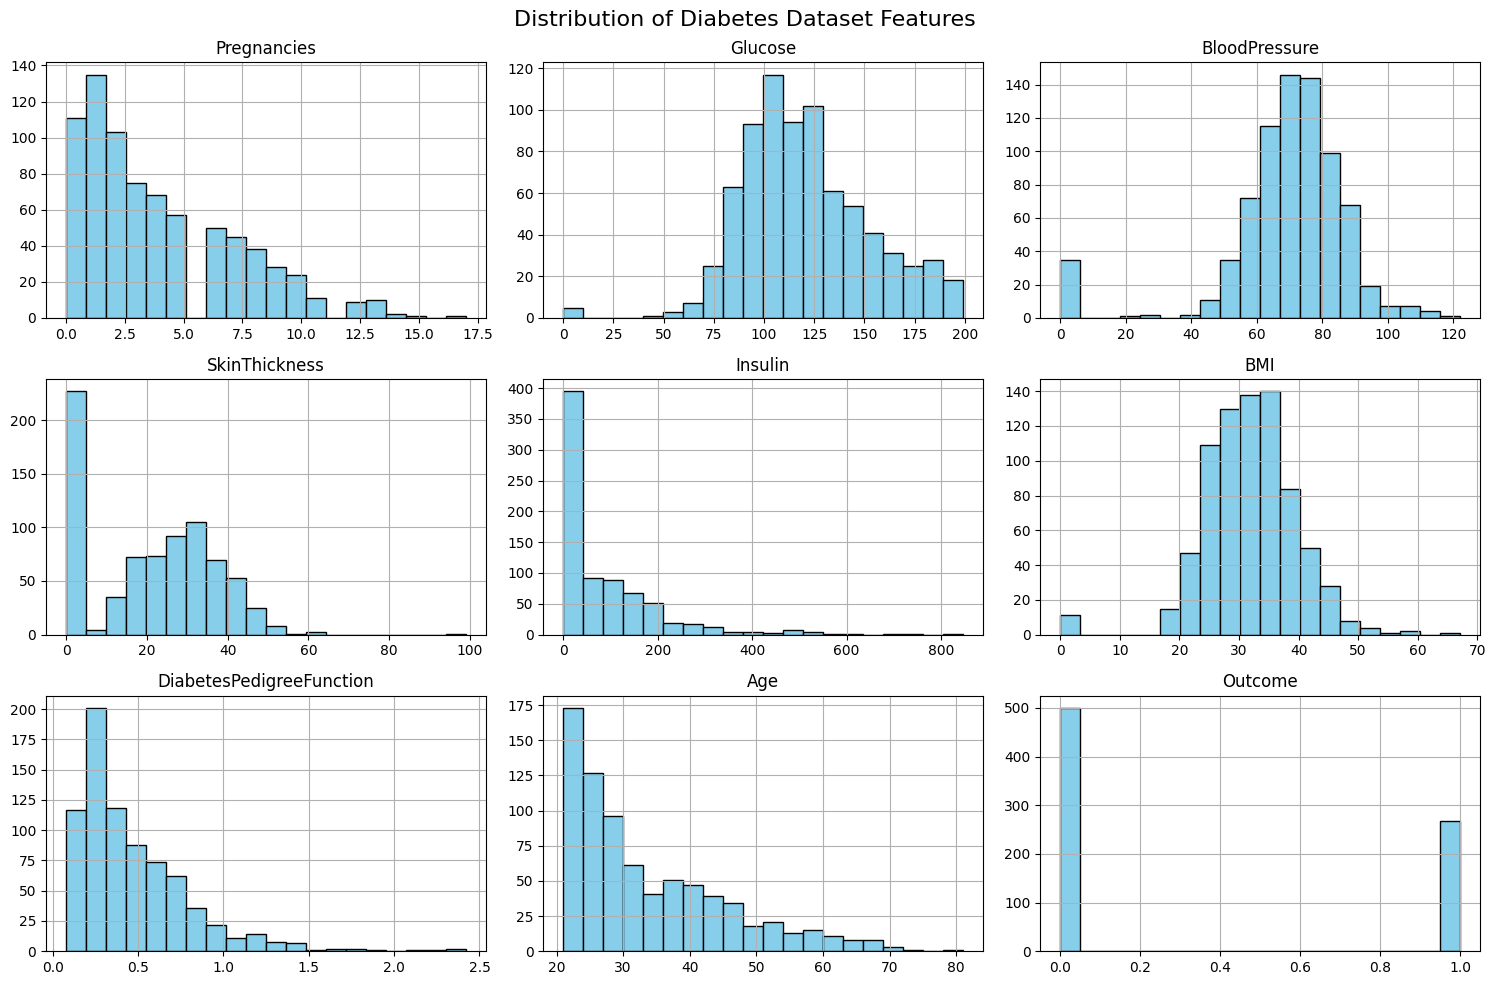

In [109]:
# Create histograms for all numerical features

df.hist(figsize=(15, 10), bins=20, color='skyblue', edgecolor='black')

# Add title to the visualization
plt.suptitle("Distribution of Diabetes Dataset Features", fontsize=16)

# Adjust layout
plt.tight_layout()

# Display the plots
plt.show()

In [110]:
#Histograms show the distribution of different numerical features in the Diabetes dataset.

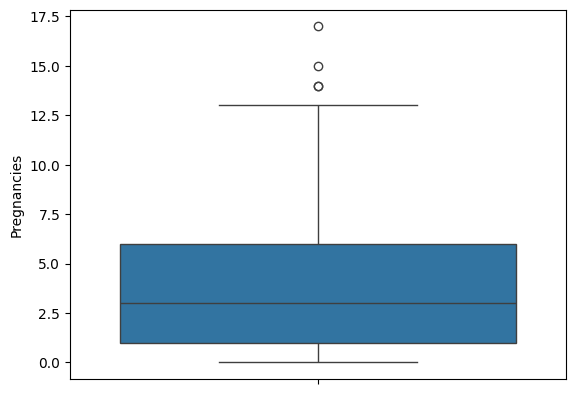

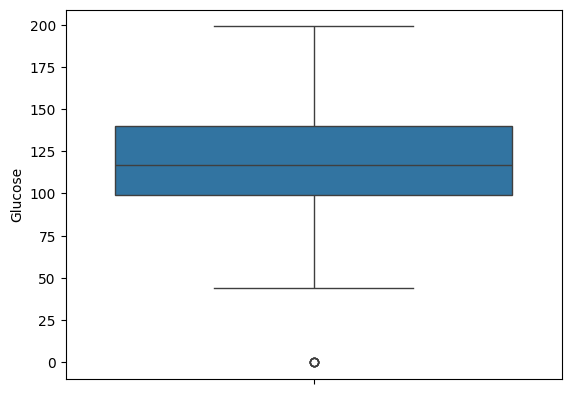

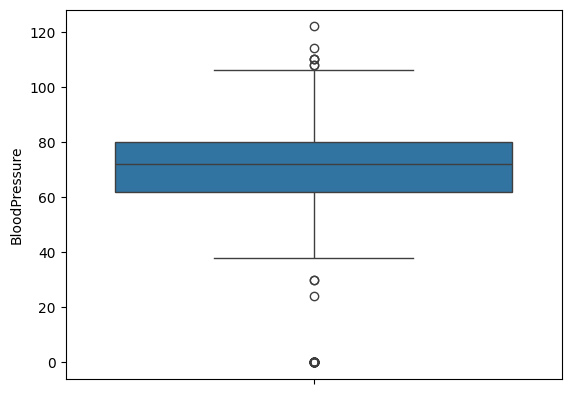

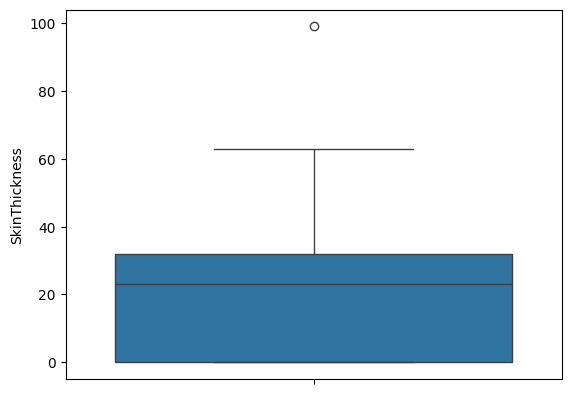

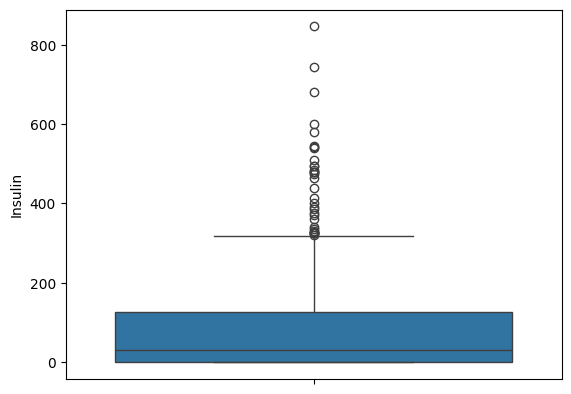

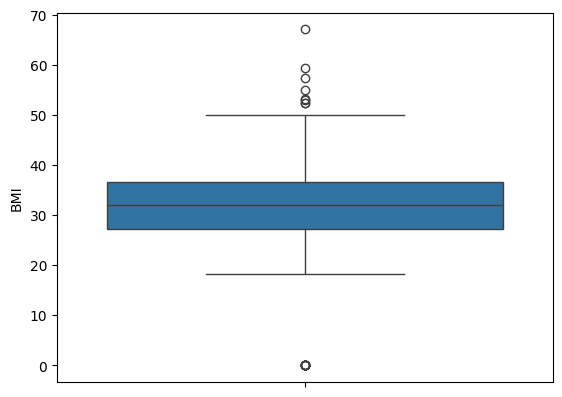

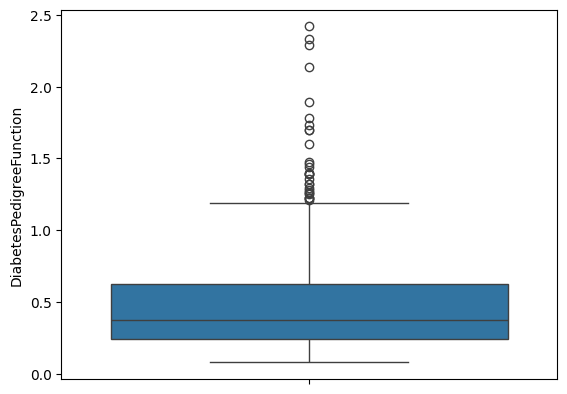

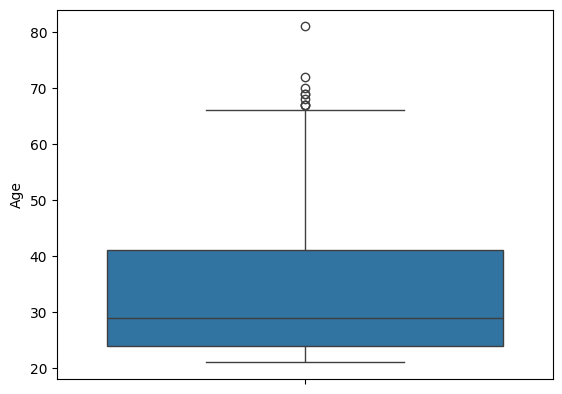

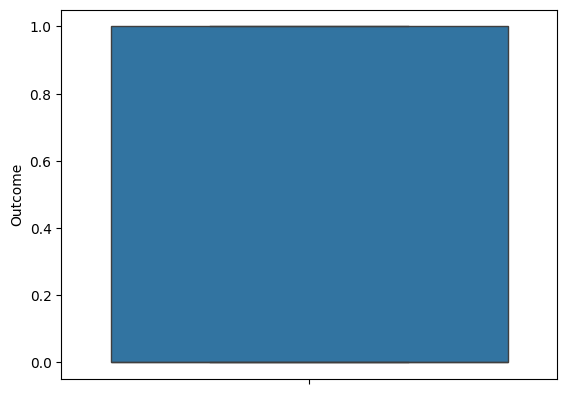

In [111]:
#Boxplot
#To check outliers
for i in df.select_dtypes(include=['int64', 'float64']).columns:
    sns.boxplot(df[i])
    plt.show()

In [112]:
#Outlier Capping
for i in df.select_dtypes(include=['int64', 'float64']).columns:
    q1=df[i].quantile(0.25)
    q3=df[i].quantile(0.75)
    IQR=q3-q1
    LB=q1-1.5*IQR
    UB=q3+1.5*IQR
    df[i]=df[i].clip(LB,UB)

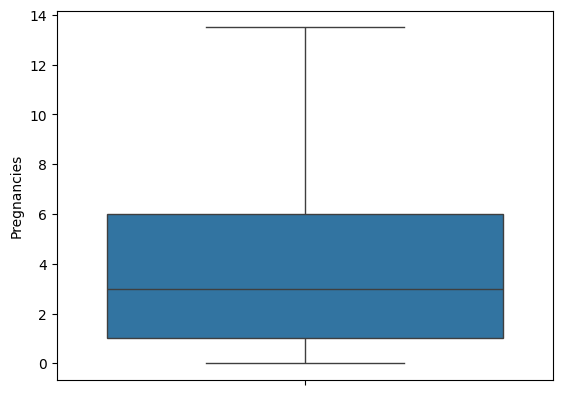

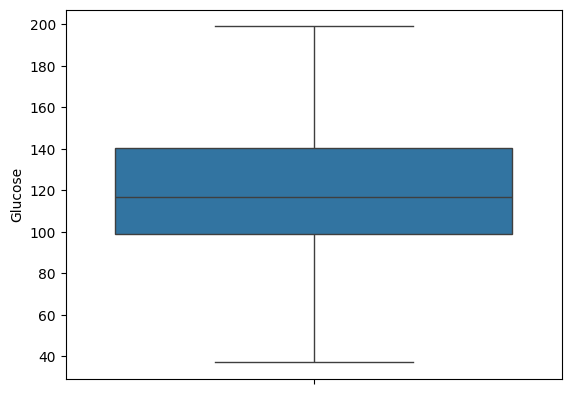

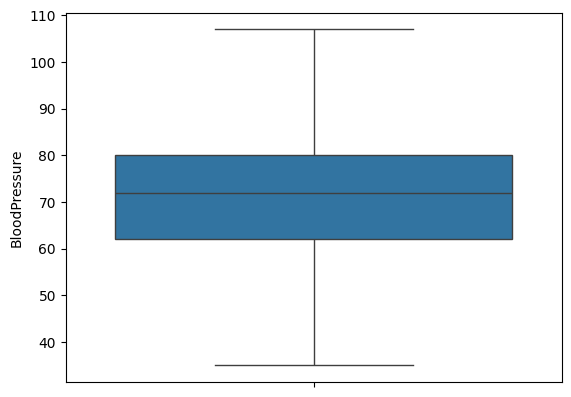

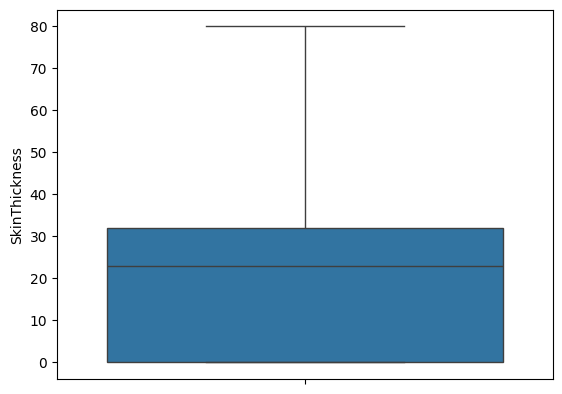

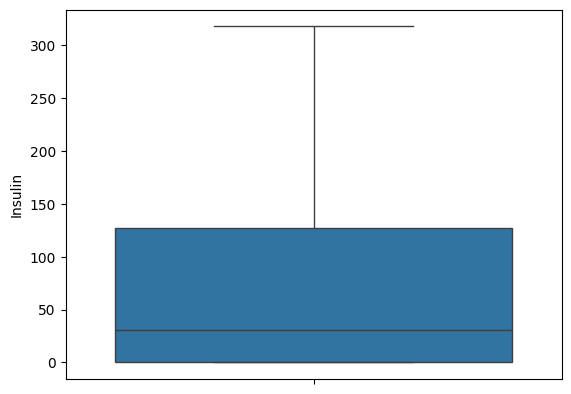

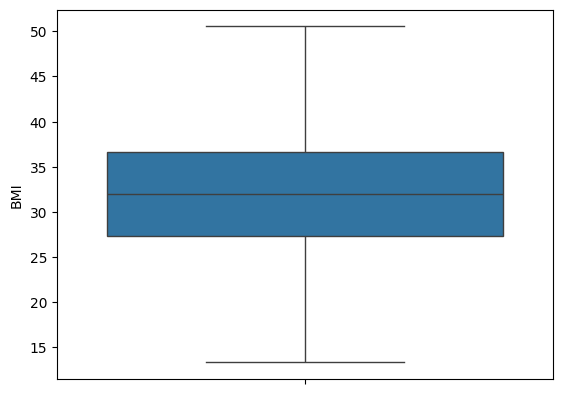

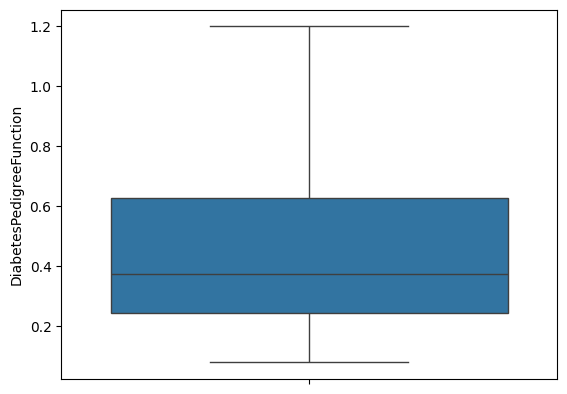

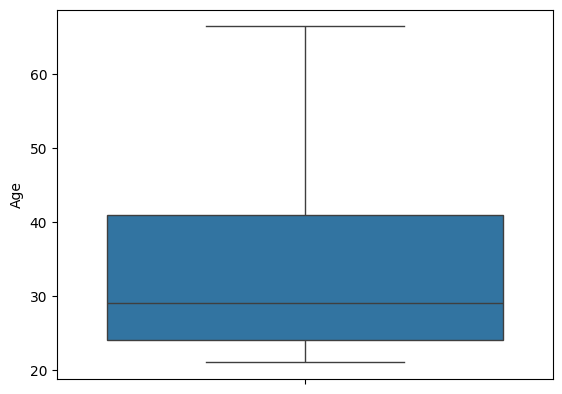

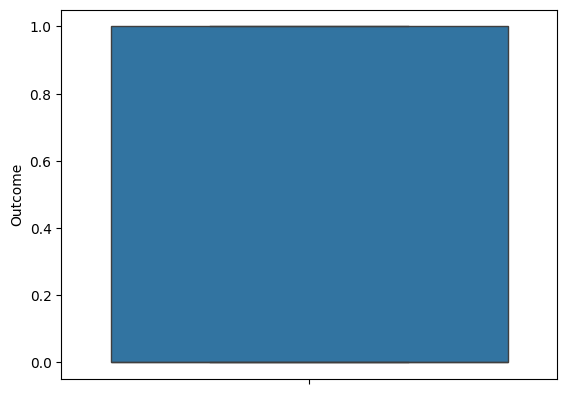

In [113]:
#To check outliers
for i in df.select_dtypes(include=['int64', 'float64']).columns:
    sns.boxplot(df[i])
    plt.show()

In [114]:
#Box plots help identify potential outliers in the Diabetes dataset.
#Some features, such as Insulin, SkinThickness, and DiabetesPedigreeFunction, may contain extreme values.
#These outliers can be further investigated during data preprocessing.

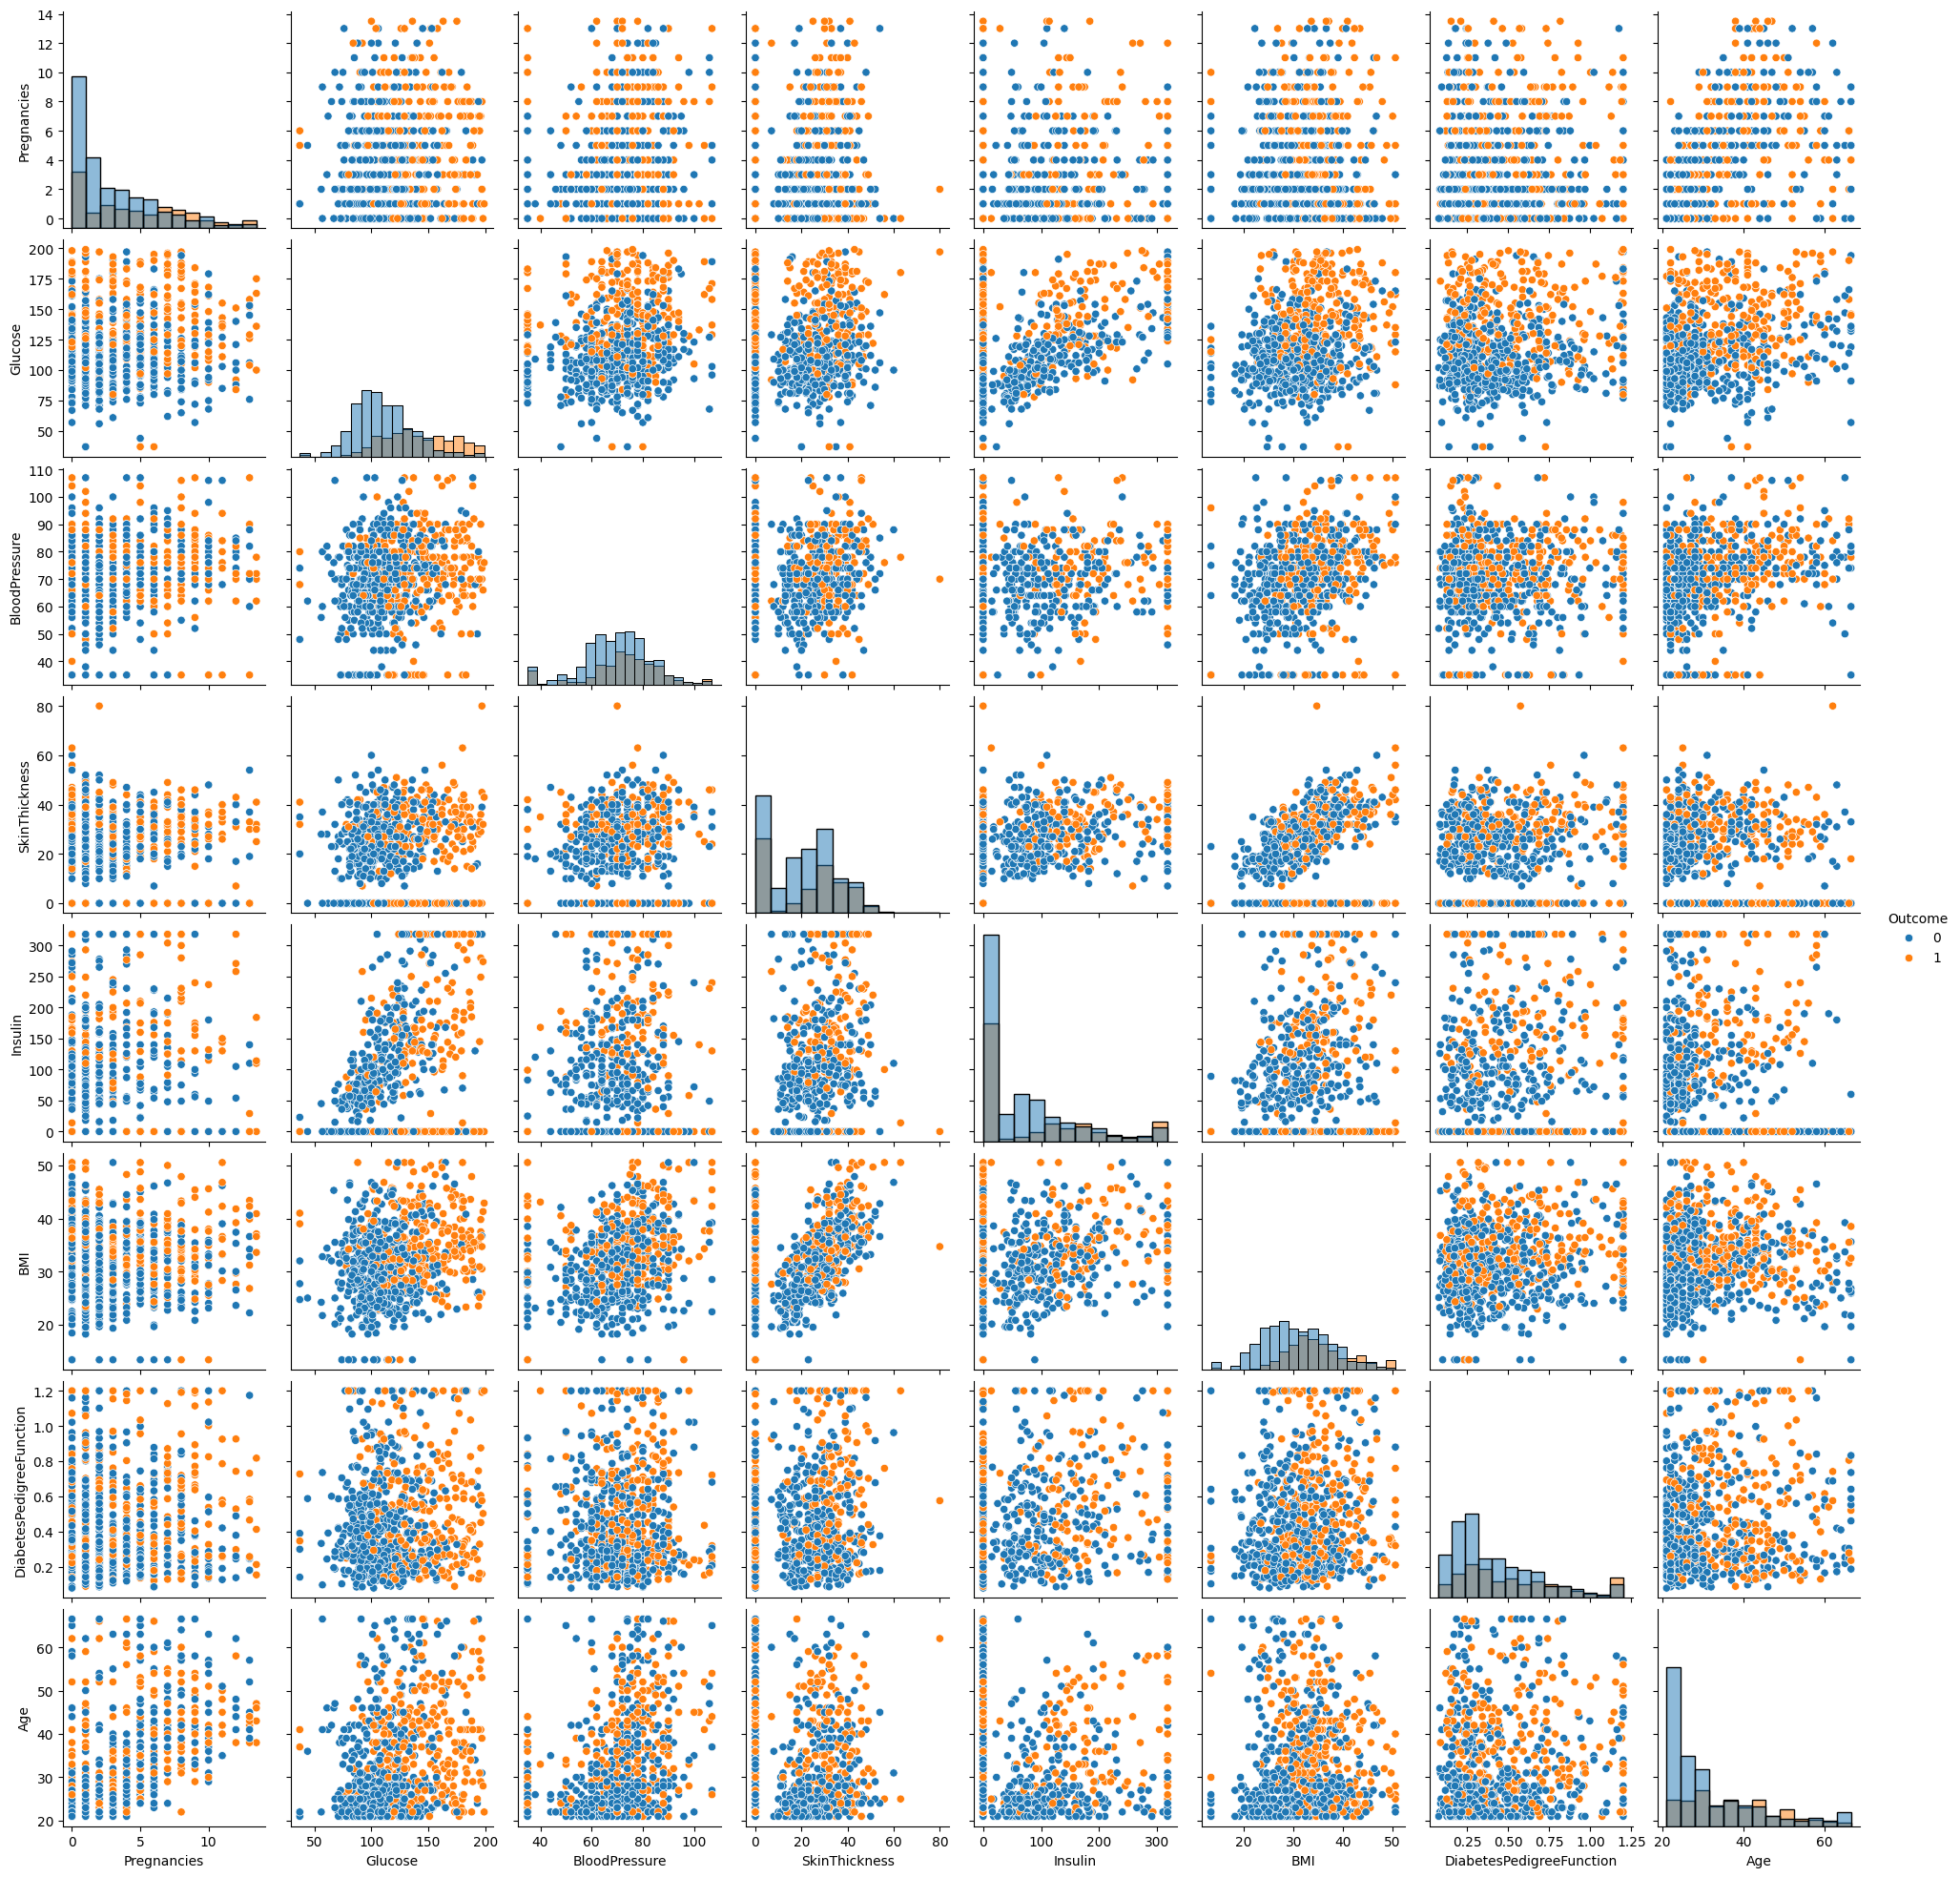

In [115]:
# Create pair plot to visualize relationships between features

sns.pairplot(df, hue='Outcome', diag_kind='hist')

# Display the pair plot
plt.show()

In [116]:
#Pair plots show the relationships between different numerical features.
#The Outcome variable helps distinguish diabetic and non-diabetic patients.
#Some features show overlapping distributions between the two groups.
#Pair plots help identify possible patterns and relationships among features.

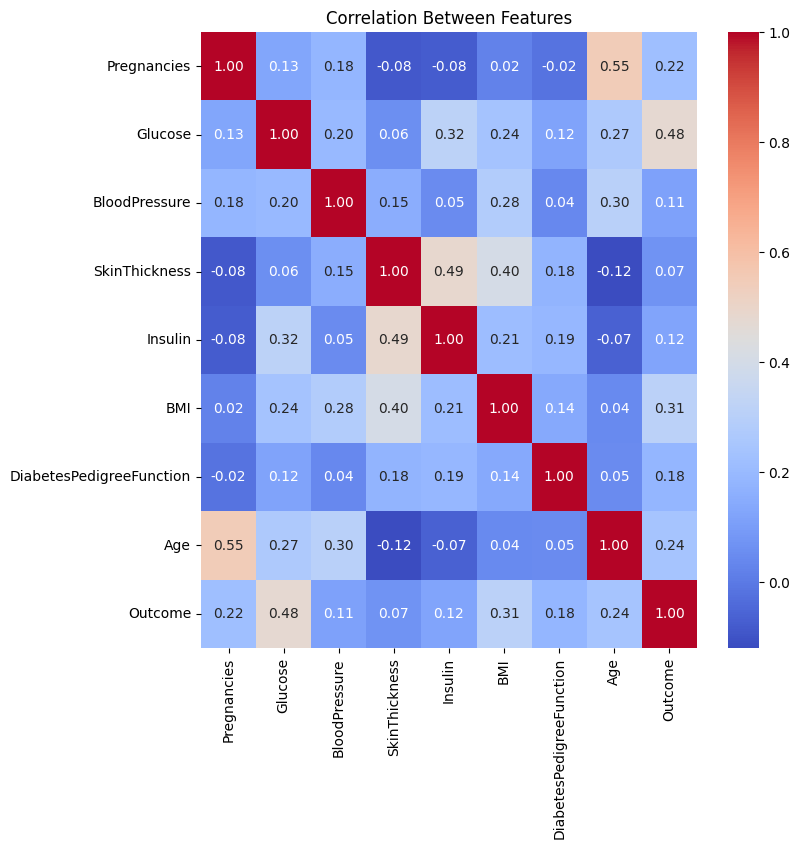

In [117]:
# Calculate correlation between all features
correlation = df.corr()

# Visualize relationships using a heatmap

plt.figure(figsize=(8, 8))

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

# Add title
plt.title("Correlation Between Features")

# Display the heatmap
plt.show()

In [118]:
#The correlation heatmap shows the relationships between different features.

In [119]:
#Analyze any patterns or correlations observed in the data.

In [120]:
#Patterns and Correlations Observed
#Glucose has a positive correlation with the Outcome variable.
#BMI and Age also show positive correlations with Outcome.
#Pregnancies and Age show a positive correlation.
#Insulin and SkinThickness are positively correlated.
#Most features show weak to moderate correlations with each other.
#Glucose is an important feature for predicting diabetes.
#Overall, the analysis helps us understand the patterns and relationships between different features in the Diabetes dataset.

In [121]:
#2. Data Preprocessing:

In [122]:
#a. Handle missing values (e.g., imputation).

In [123]:
# Check missing values in each column
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [124]:
#b. Encode categorical variables.

In [125]:
# Check categorical columns
df.select_dtypes(include=['object']).columns

Index([], dtype='object')

In [126]:
#Conclusion:
#Categorical variables were checked using select_dtypes().
#No object-type categorical columns were found.
#The Outcome column was already encoded as 0 and 1.
#Therefore, no additional encoding was required.

In [127]:
#3. Model Building:

In [128]:
#a. Build a logistic regression model using appropriate libraries (e.g., scikit-learn).

In [129]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [130]:
#split the dataset into features and target
x=df.drop(columns=['Outcome'])
y=df['Outcome']

In [131]:
x

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6.0,148.0,72,35,0.0,33.6,0.627,50.0
1,1.0,85.0,66,29,0.0,26.6,0.351,31.0
2,8.0,183.0,64,0,0.0,23.3,0.672,32.0
3,1.0,89.0,66,23,94.0,28.1,0.167,21.0
4,0.0,137.0,40,35,168.0,43.1,1.200,33.0
...,...,...,...,...,...,...,...,...
763,10.0,101.0,76,48,180.0,32.9,0.171,63.0
764,2.0,122.0,70,27,0.0,36.8,0.340,27.0
765,5.0,121.0,72,23,112.0,26.2,0.245,30.0
766,1.0,126.0,60,0,0.0,30.1,0.349,47.0


In [132]:
y

,Outcome
0,1
1,0
2,1
3,0
4,1
...,...
763,0
764,0
765,0
766,1


In [133]:
#split the datset into
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [134]:
x_train

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
60,2.0,84.0,35,0,0.000,13.35,0.304,21.0
618,9.0,112.0,82,24,0.000,28.20,1.200,50.0
346,1.0,139.0,46,19,83.000,28.70,0.654,22.0
294,0.0,161.0,50,0,0.000,21.90,0.254,65.0
231,6.0,134.0,80,37,318.125,46.20,0.238,46.0
...,...,...,...,...,...,...,...,...
71,5.0,139.0,64,35,140.000,28.60,0.411,26.0
106,1.0,96.0,107,0,0.000,22.40,0.207,27.0
270,10.0,101.0,86,37,0.000,45.60,1.136,38.0
435,0.0,141.0,35,0,0.000,42.40,0.205,29.0


In [135]:
x_test

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
668,6.0,98.0,58,33,190.000,34.0,0.430,43.0
324,2.0,112.0,75,32,0.000,35.7,0.148,21.0
624,2.0,108.0,64,0,0.000,30.8,0.158,21.0
690,8.0,107.0,80,0,0.000,24.6,0.856,34.0
473,7.0,136.0,90,0,0.000,29.9,0.210,50.0
...,...,...,...,...,...,...,...,...
355,9.0,165.0,88,0,0.000,30.4,0.302,49.0
534,1.0,77.0,56,30,56.000,33.3,1.200,24.0
344,8.0,95.0,72,0,0.000,36.8,0.485,57.0
296,2.0,146.0,70,38,318.125,28.0,0.337,29.0


In [136]:
y_train

,Outcome
60,0
618,1
346,0
294,0
231,1
...,...
71,0
106,0
270,1
435,1


In [137]:
y_test

,Outcome
668,0
324,0
624,0
690,0
473,0
...,...
355,1
534,0
344,0
296,1


In [138]:
#Apply Feature Scaling
scaler = StandardScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)
scaler = StandardScaler()

print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)

Training Data Shape: (614, 8)
Testing Data Shape: (154, 8)


In [139]:
#Build Logistic Regression Model
model = LogisticRegression()
model.fit(x_train, y_train)

LogisticRegression()

In [140]:
#Make Prediction
y_pred = model.predict(x_test)

print(y_pred)

[0 0 0 0 0 0 0 1 1 1 0 1 0 0 0 0 0 0 1 1 0 0 1 0 1 1 0 0 0 0 1 1 1 1 1 1 1
 0 0 1 0 1 1 0 0 1 1 0 0 1 0 1 1 0 0 0 1 0 0 1 1 0 0 0 0 1 0 1 0 1 1 0 0 0
 0 1 0 0 0 0 1 0 0 0 0 1 1 0 0 0 0 0 0 0 1 1 0 0 1 0 1 0 1 0 1 0 0 1 0 1 0
 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 0 0 1 0 0 1 1 0 0 0 0 0 0 0 0 0
 0 1 0 1 0 0]


In [141]:
#Check model Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 75.32467532467533 %


In [142]:
#b. Train the model using the training data.

In [143]:
# Model was already trained using x_train and y_train
# in the previous step. No retraining is required.

In [144]:
#checking the training accuracy
train_accuracy = model.score(x_train, y_train)
print("Training Accuracy:", train_accuracy * 100, "%")

Training Accuracy: 78.0130293159609 %


In [145]:
#4. Model Evaluation:

In [146]:
#a. Evaluate the performance of the model on the testing data using accuracy, precision, recall, F1-score, and ROC-AUC score.

In [147]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score

In [148]:
#Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.7532467532467533


In [149]:
#Calculate Precision
precision = precision_score(y_test, y_pred)

print("Precision:", precision)

Precision: 0.6545454545454545


In [150]:
#Calculate Recall
recall = recall_score(y_test, y_pred)

print("Recall:", recall)

Recall: 0.6545454545454545


In [151]:
#Calculate F1 Score
f1 = f1_score(y_test, y_pred)

print("F1-Score:", f1)

F1-Score: 0.6545454545454545


In [152]:
#Calculate ROC_AUC Score
y_prob = model.predict_proba(x_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.8143250688705235


In [153]:
print("Model Evaluation Results")

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))
print("ROC-AUC Score:", roc_auc_score(y_test, y_prob))


Model Evaluation Results
Accuracy: 0.7532467532467533
Precision: 0.6545454545454545
Recall: 0.6545454545454545
F1-Score: 0.6545454545454545
ROC-AUC Score: 0.8143250688705235


In [154]:
#Visualize the ROC curve.

In [155]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

In [156]:
#Calculate FPR and TPR
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = auc(fpr, tpr)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.8143250688705235


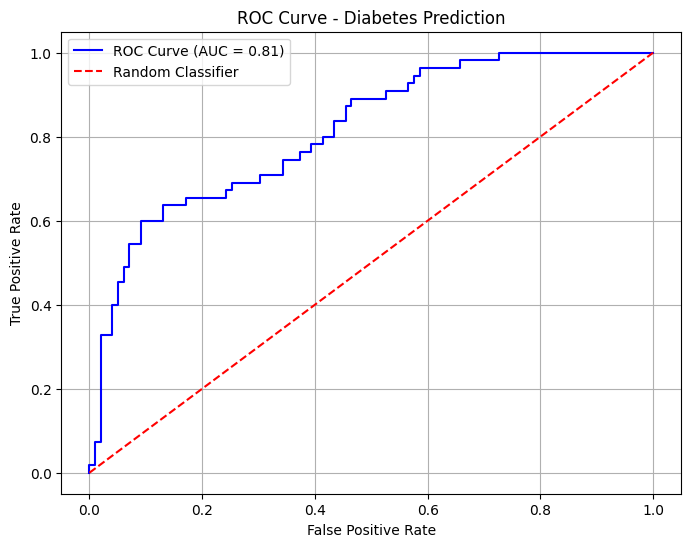

In [157]:
#Visualize ROC Curve
plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, color='blue',
         label='ROC Curve (AUC = %0.2f)' % roc_auc)

plt.plot([0, 1], [0, 1], color='red', linestyle='--',
         label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('ROC Curve - Diabetes Prediction')

plt.legend()
plt.grid()

plt.show()

In [158]:
#5. Interpretation:

In [159]:
#a. Interpret the coefficients of the logistic regression model.

In [160]:
coefficients = pd.DataFrame({
    'Feature': x.columns,
    'Coefficient': model.coef_[0]
})

print(coefficients)

                    Feature  Coefficient
0               Pregnancies     0.196465
1                   Glucose     1.083772
2             BloodPressure    -0.244168
3             SkinThickness     0.035714
4                   Insulin    -0.216714
5                       BMI     0.772729
6  DiabetesPedigreeFunction     0.281207
7                       Age     0.438189


In [161]:
#Interpret the Logistic Regression coefficients to understand the effect
# of each feature on diabetes prediction.
# Positive coefficients increase the predicted likelihood of diabetes,
# while negative coefficients decrease it, keeping other features constant.
# Glucose and BMI have comparatively large positive coefficients,
# indicating a strong influence on the model's predictions.

In [162]:
#b. Discuss the significance of features in predicting the target variable (survival probability in this case).

In [163]:
#Significance of features in predicting diabetes probability
# Glucose (1.08) is the most significant feature, followed by BMI (0.77) and Age (0.43).
# Higher Glucose and BMI strongly increase the risk of diabetes.
# DiabetesPedigreeFunction and Pregnancies have moderate significance.
# BloodPressure and Insulin show negative coefficients due to zero values in data.

In [164]:
#6. Deployment with Streamlit:

In [165]:
#In this task, you will deploy your logistic regression model using Streamlit. The deployment can be done locally or online via Streamlit Share. Your task includes creating a Streamlit app in Python that involves loading your trained model and setting up user inputs for predictions.

#(optional)For online deployment, use Streamlit Community Cloud, which supports deployment from GitHub repositories.
#Detailed deployment instructions are available in the Streamlit Documentation.
#https://docs.streamlit.io/streamlit-community-cloud/deploy-your-app

In [166]:
import joblib
joblib.dump(model,"model.pkl")

['model.pkl']

In [167]:
# Save scaler
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

In [168]:
import os
import joblib

# In interactive environments like Colab, we use os.getcwd() instead of __file__
BASE_DIR = os.getcwd()

model_path = os.path.join(BASE_DIR, "model.pkl")

model = joblib.load(model_path)

In [169]:
%%writefile app.py
import streamlit as st
import numpy as np
import joblib
import os

# Page setup
st.set_page_config(page_title="Diabetes Prediction App", layout="centered")
st.title("🩺 Diabetes Prediction App")
st.write("Enter the patient's information below to predict the likelihood of diabetes.")

# Load pre-trained model and scaler
@st.cache_resource
def load_assets():
    model = joblib.load("model.pkl")
    scaler = joblib.load("scaler.pkl")
    return model, scaler

try:
    model, scaler = load_assets()
except Exception as e:
    st.error(f"Error loading model or scaler files: {e}")
    st.stop()

# Layout inputs
col1, col2 = st.columns(2)

with col1:
    pregnancies = st.number_input("Pregnancies", min_value=0, max_value=20, value=1)
    glucose = st.number_input("Glucose Level", min_value=0, max_value=300, value=120)
    blood_pressure = st.number_input("Blood Pressure (mm Hg)", min_value=0, max_value=200, value=70)
    skin_thickness = st.number_input("Skin Thickness (mm)", min_value=0, max_value=100, value=20)

with col2:
    insulin = st.number_input("Insulin Level (mu U/ml)", min_value=0, max_value=900, value=80)
    bmi = st.number_input("BMI", min_value=0.0, max_value=70.0, value=25.0, format="%.1f")
    dpf = st.number_input("Diabetes Pedigree Function", min_value=0.0, max_value=3.0, value=0.5, format="%.3f")
    age = st.number_input("Age", min_value=1, max_value=120, value=30)

# Make prediction
if st.button("Predict Diabetes Risk", type="primary"):
    # Assemble inputs into matching array format
    raw_inputs = np.array([[pregnancies, glucose, blood_pressure, skin_thickness, insulin, bmi, dpf, age]])

    # Scaler transformation
    scaled_inputs = scaler.transform(raw_inputs)

    # Model prediction & probability
    prediction = model.predict(scaled_inputs)[0]
    probability = model.predict_proba(scaled_inputs)[0][1]

    # Visual separator
    st.markdown("---")

    if prediction == 1:
        st.error(f"🚨 **High Risk of Diabetes** (Confidence: {probability:.2%})")
        st.warning("The model suggests the patient may be diabetic. Please consult a healthcare professional.")
    else:
        st.success(f"✨ **Low Risk of Diabetes** (Confidence: {1 - probability:.2%})")
        st.info("The model suggests the patient is unlikely to be diabetic.")


Overwriting app.py
